<a href="https://colab.research.google.com/github/adamcramer400/cvd-women--team-trench-/blob/main/track-02/team/notebooks/02_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 Analysis: Track 2, Cardiovascular Health in Women

This notebook follows steps 3 to 7 of the [workflow](../../3-workflow.md): explore, build a model, check it, interpret and make a headline visual.

Run `01_cleaning.ipynb` first. Settings marked **You decide** start as `None`.

In [1]:
# Setup: run this cell first. It finds the track folder and the data.
import re, sys, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PUBLIC_REPO = "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git"
IN_COLAB = "google.colab" in sys.modules

def find_track_dir():
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "track-02" / "data").is_dir():
            return folder / "track-02"
        if folder.name == "track-02" and (folder / "data").is_dir():
            return folder
    if IN_COLAB:
        dest = Path("/content/openbio-datathon-2026")
        if not dest.exists():
            subprocess.run(["git", "clone", "--depth", "1", PUBLIC_REPO, str(dest)], check=True)
        return dest / "track-02"
    return None

TRACK = find_track_dir()
TEAM = TRACK / "team" if TRACK else Path.cwd()
CLEAN = TEAM / "data_clean"
FIGURES = TEAM / "figures"
for folder in (CLEAN, FIGURES, TEAM / "docs"):
    folder.mkdir(parents=True, exist_ok=True)

SEARCH_DIRS = [d for d in [TRACK / "data" if TRACK else None, TRACK / "data" / "gbd" if TRACK else None,
               Path.cwd(), Path("/content"), Path("/content/drive/MyDrive/datathon")] if d]

def missing(name):
    print(f"Fill in {name} in the cell above, then rerun this cell.")

print("Track folder:", TRACK)
print("Team folder: ", TEAM)
if IN_COLAB:
    print("On Colab, outputs are saved in this session only. Download them or copy them into your team repository.")


Track folder: /content/openbio-datathon-2026/track-02
Team folder:  /content/openbio-datathon-2026/track-02/team
On Colab, outputs are saved in this session only. Download them or copy them into your team repository.


## Step 1: Your question

**You decide:**

- `QUESTION`: one sentence, also written in your team README.
- `DATASET`: `"d1"`, `"d2"`, `"s1"`, `"s2"` or `"s2_long"`.
- `OUTCOME`: the column you want to explain.
- `PREDICTORS`: a list of columns. Wrap ordered or text categories in `C()`, for example `"C(cholesterol_level)"`.
- `MODEL`: `"logistic"` for a yes/no outcome or `"linear"` for a number.

In [2]:
QUESTION = "Among women aged 30 to 65, do cholesterol and glucose levels tell us anything about cardiovascular disease beyond age and blood pressure?"
DATASET = "d1"
OUTCOME = "cardio"
PREDICTORS = ["age_years", "ap_hi", "C(cholesterol_level)", "C(gluc_level)"]
#   PREDICTORS = ["age_years", "ap_hi", "C(cholesterol_level)"]
#   PREDICTORS = ["age_years", "ap_hi", "C(gluc_level)"]
#   PREDICTORS = ["age_years", "ap_hi"]
MODEL = "logistic"

READY = all(v is not None for v in (QUESTION, DATASET, OUTCOME, PREDICTORS, MODEL))
if not READY:
    print("Fill in QUESTION, DATASET, OUTCOME, PREDICTORS and MODEL, then rerun the notebook.")
    print("Example: DATASET='d1', OUTCOME='cardio', PREDICTORS=['age_years', 'C(cholesterol_level)'], MODEL='logistic'")


In [3]:
# Rebuild the cleaned Dataset 1 file if 01_cleaning.ipynb has not been run in this session.
# These are the same rules, in the same order, as 01_cleaning.ipynb and docs/cleaning_log.md.
clean_path = CLEAN / "d1_clean.csv"
if clean_path.exists():
    print("Found d1_clean.csv written by 01_cleaning.ipynb.")
else:
    d1 = pd.read_csv(TRACK / "data" / "cardiovascular_dataset_OpenBio_Final.csv", sep=";")
    d1 = d1.drop_duplicates(subset="id")
    d1["age_years"] = d1["age"] / 365.25
    d1 = d1.drop_duplicates(subset=[c for c in d1.columns if c not in ("id", "age_years")])
    d1["female"] = (d1["gender"] == 1).astype(int)
    d1 = d1[d1["female"] == 1].copy()
    for col, (low, high) in {"ap_hi": (70, 250), "ap_lo": (40, 150), "height": (130, 200), "weight": (35, 200)}.items():
        d1 = d1[d1[col].between(low, high)]
    d1 = d1[d1["ap_hi"] > d1["ap_lo"]].copy()
    d1["bmi"] = d1["weight"] / (d1["height"] / 100) ** 2
    for col in ("cholesterol", "gluc"):
        d1[col + "_level"] = d1[col].map({1: "normal", 2: "above normal", 3: "well above normal"})
    d1.to_csv(clean_path, index=False)
    print(f"Rebuilt d1_clean.csv from the raw file using the rules in 01_cleaning.ipynb: {len(d1):,} rows.")

Rebuilt d1_clean.csv from the raw file using the rules in 01_cleaning.ipynb: 44,639 rows.


In [4]:
df = None
if READY:
    path = CLEAN / f"{DATASET}_clean.csv"
    if not path.exists():
        print(f"{path.name} not found. Run 01_cleaning.ipynb first.")
        READY = False
    else:
        df = pd.read_csv(path)
        for col in [c for c in df.columns if c.endswith("_level")]:
            order = {"cholesterol_level": ["normal", "above normal", "well above normal"],
                     "gluc_level": ["normal", "above normal", "well above normal"],
                     "alcohol_level": ["None", "Light", "Moderate", "Heavy"],
                     "diet_level": ["Unhealthy", "Average", "Healthy"]}.get(col)
            if order:
                df[col] = pd.Categorical(df[col], categories=order, ordered=True)
        print(QUESTION)
        print(f"Loaded {len(df):,} rows from {path.name}")


Among women aged 30 to 65, do cholesterol and glucose levels tell us anything about cardiovascular disease beyond age and blood pressure?
Loaded 44,639 rows from d1_clean.csv


## Step 2: Explore

Sample size, summary statistics and each predictor plotted against the outcome. Note anything surprising.

Rows with no missing values in these columns: 44,639 of 44,639


,cardio,age_years,ap_hi,cholesterol_level,gluc_level
count,44639.00,44639.00,44639.00,44639,44639
unique,NaN,NaN,NaN,3,3
top,NaN,NaN,NaN,normal,normal
freq,NaN,NaN,NaN,32962,37729
mean,0.49,53.41,125.92,NaN,NaN
std,0.50,6.66,16.72,NaN,NaN
min,0.00,29.73,70.00,NaN,NaN
25%,0.00,49.38,120.00,NaN,NaN
50%,0.00,54.00,120.00,NaN,NaN
75%,1.00,58.39,140.00,NaN,NaN


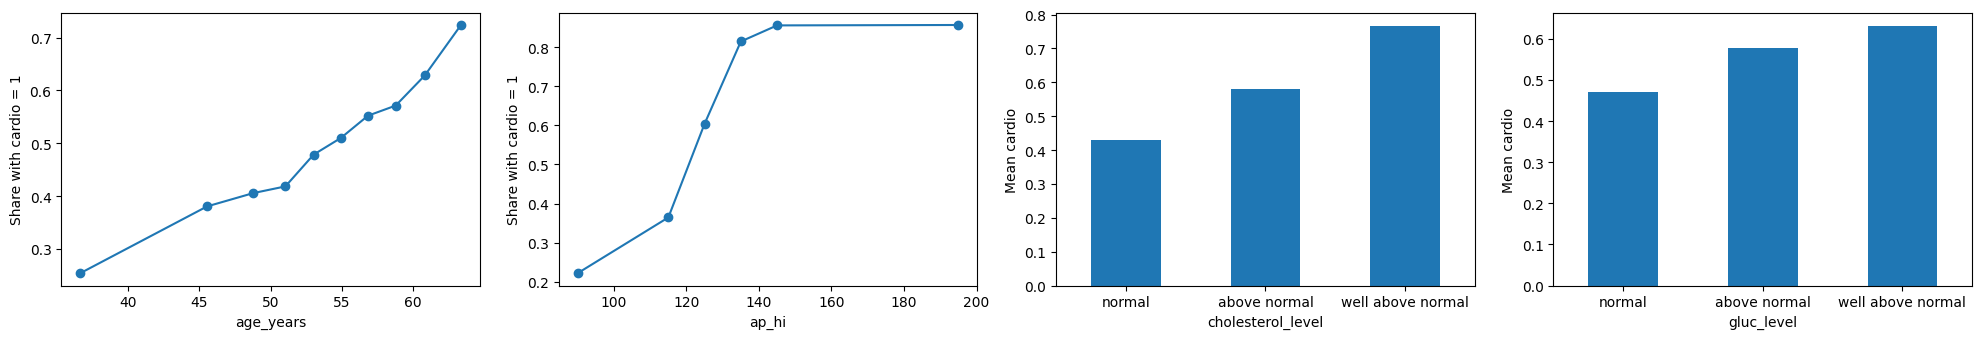

In [5]:
def base_column(term):
    m = re.match(r"C\((\w+)", term)
    return m.group(1) if m else term

def nice_term(term):
    """'C(cholesterol_level)[T.above normal]' -> 'cholesterol_level: above normal'."""
    m = re.match(r"C\((\w+)[^)]*\)\[T\.(.+)\]", term)
    return f"{m.group(1)}: {m.group(2)}" if m else term

if READY:
    cols = [OUTCOME] + [base_column(p) for p in PREDICTORS]
    data = df[cols].dropna()
    print(f"Rows with no missing values in these columns: {len(data):,} of {len(df):,}")
    display(data.describe(include="all").round(2))

    fig, axes = plt.subplots(1, len(PREDICTORS), figsize=(5 * len(PREDICTORS), 3.5), squeeze=False)
    for ax, term in zip(axes[0], PREDICTORS):
        col = base_column(term)
        if term.startswith("C(") or data[col].nunique() <= 10:
            data.groupby(col, observed=True)[OUTCOME].mean().plot.bar(ax=ax, rot=0)
            ax.set_ylabel(f"Mean {OUTCOME}")
        elif MODEL == "logistic":
            binned = pd.qcut(data[col], 10, duplicates="drop")
            share = data.groupby(binned, observed=True)[OUTCOME].mean()
            ax.plot([b.mid for b in share.index], share.values, marker="o")
            ax.set_ylabel(f"Share with {OUTCOME} = 1")
        else:
            sample = data.sample(min(len(data), 3000), random_state=0)
            ax.scatter(sample[col], sample[OUTCOME], s=5, alpha=0.3)
            ax.set_ylabel(OUTCOME)
        ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()




*   complete data for all 44,639 patients
*   49% mean for CVD suggests prevalence cannot be determined

*   CVD rises steadily with age
*   CVD rises sharply with systolic bp -- biggest jump between 120-140, ~37% to ~82%
*   CVD rises steadily at each cholesterol level: ~42% normal, ~58% above normal, ~75% well above normal
*   CVD has smaller rise with glucose levels: ~47% normal, ~55% above normal, ~61% well above normal
*   Next step: compare for glucose and cholesterol after accounting for age and BP.





### Summary statistics used in the presentation

Sample size, averages and the raw CVD rate in each group. These are the numbers on the "raw patterns" slide.

In [ ]:
if READY:
    s = df
    print(f"Women analyzed: {len(s):,}")
    print(f"Average age: {s['age_years'].mean():.1f} years (SD {s['age_years'].std():.1f})")
    print(f"Average systolic BP: {s['ap_hi'].mean():.1f} mmHg (SD {s['ap_hi'].std():.1f})")
    print(f"Share with CVD: {100 * s[OUTCOME].mean():.1f}%")
    print(f"Cholesterol above normal (either higher level): {100 * (s['cholesterol_level'] != 'normal').mean():.1f}%")
    print(f"Glucose above normal (either higher level): {100 * (s['gluc_level'] != 'normal').mean():.1f}%")
    sbp_bands = pd.cut(s["ap_hi"], [0, 119, 129, 139, 149, 999],
                       labels=["<120", "120-129", "130-139", "140-149", "150+"])
    for name, groups in [("systolic BP band", sbp_bands), ("cholesterol level", s["cholesterol_level"]),
                         ("glucose level", s["gluc_level"])]:
        t = s.groupby(groups, observed=True)[OUTCOME].agg(["size", "mean"])
        t["CVD %"] = (100 * t["mean"]).round(1)
        print(f"\nCVD % by {name}:")
        display(t[["size", "CVD %"]].rename(columns={"size": "Women"}))

## Step 3: Build the model

- **Logistic:** prints odds ratios (OR) with 95% confidence intervals and draws a forest plot. OR = 1 means no association.
- **Linear:** prints the slope and R². If you have one numeric predictor, it draws the fitted line with a confidence band.

Formula: cardio ~ age_years + ap_hi + C(cholesterol_level) + C(gluc_level)


,OR,CI low,CI high,p-value
cholesterol_level: above normal,1.452,1.361,1.550,0.000
cholesterol_level: well above normal,3.090,2.837,3.366,0.000
gluc_level: above normal,1.038,0.951,1.133,0.405
gluc_level: well above normal,0.742,0.675,0.817,0.000
age_years,1.057,1.054,1.061,0.000
ap_hi,1.064,1.062,1.066,0.000


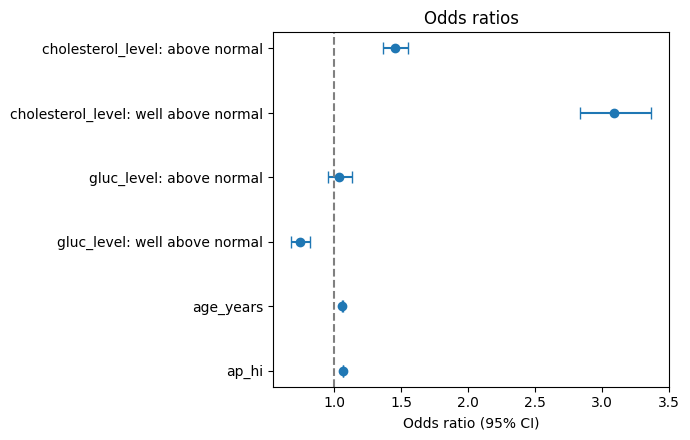

In [6]:
import statsmodels.formula.api as smf

result = None
if READY:
    formula = f"{OUTCOME} ~ " + " + ".join(PREDICTORS)
    print("Formula:", formula)
    if MODEL == "logistic":
        result = smf.logit(formula, data=data).fit(disp=False)
        table = pd.DataFrame({"OR": np.exp(result.params),
                              "CI low": np.exp(result.conf_int()[0]),
                              "CI high": np.exp(result.conf_int()[1]),
                              "p-value": result.pvalues}).drop(index="Intercept")
        table.index = [nice_term(i) for i in table.index]
        display(table.round(3))

        fig, ax = plt.subplots(figsize=(7, 0.5 * len(table) + 1.5))
        y = np.arange(len(table))[::-1]
        ax.errorbar(table["OR"], y, xerr=[table["OR"] - table["CI low"], table["CI high"] - table["OR"]],
                    fmt="o", capsize=4)
        ax.axvline(1, color="grey", linestyle="--")
        ax.set_yticks(y, table.index)
        ax.set_xlabel("Odds ratio (95% CI)")
        ax.set_title("Odds ratios")
        plt.tight_layout()
        fig.savefig(FIGURES / "forest_plot.png", dpi=200)
        plt.show()
    elif MODEL == "linear":
        result = smf.ols(formula, data=data).fit()
        table = pd.DataFrame({"Slope": result.params, "CI low": result.conf_int()[0],
                              "CI high": result.conf_int()[1], "p-value": result.pvalues})
        table.index = [nice_term(i) for i in table.index]
        display(table.round(3))
        print(f"R-squared: {result.rsquared:.3f}   n = {int(result.nobs):,}")

        if len(PREDICTORS) == 1 and not PREDICTORS[0].startswith("C("):
            x = PREDICTORS[0]
            grid = pd.DataFrame({x: np.linspace(data[x].min(), data[x].max(), 100)})
            band = result.get_prediction(grid).summary_frame(alpha=0.05)
            sample = data.sample(min(len(data), 3000), random_state=0)
            fig, ax = plt.subplots(figsize=(7, 4.5))
            ax.scatter(sample[x], sample[OUTCOME], s=6, alpha=0.3)
            ax.plot(grid[x], band["mean"], color="C1")
            ax.fill_between(grid[x], band["mean_ci_lower"], band["mean_ci_upper"], color="C1", alpha=0.3)
            ax.set_xlabel(x)
            ax.set_ylabel(OUTCOME)
            ax.set_title(f"Slope {result.params[x]:.2f}, R\u00b2 {result.rsquared:.2f}")
            plt.tight_layout()
            fig.savefig(FIGURES / "regression_line.png", dpi=200)
            plt.show()
    else:
        print('MODEL must be "logistic" or "linear".')


Step 3 Observations -- adjusted for age/BP
*   Cholesterol above normal vs normal: OR 1.45 (95% CI 1.36 to 1.55), p < 0.001
*   Cholesterol well above normal vs normal: OR 3.09 (95% CI 2.84 to 3.37), p < 0.001
*   Glucose above normal vs normal: OR 1.04 (95% CI 0.95 to 1.13), p = 0.41 (no clear association)
*   Glucose well above normal vs normal: OR 0.74 (95% CI 0.68 to 0.82), p < 0.001 (opposite of what expects)
*   Age: OR 1.057 per year (~1.7x the odds per 10 years), p < 0.001
*   Systolic BP: OR 1.064 per mmHg (~1.9x the odds per 10 mmHg), p < 0.001

Summary:

Cholesterol is strongly associated with CVD even at the same age and blood pressure. Women with well above normal cholesterol had about 3 times the odds of CVD compared with women with normal cholesterol, and the odds rise step by step with each cholesterol level.

Glucose rose with CVD in Step 2, but it is not positively associated once cholesterol, age and BP are in the model. This is likely because high glucose and high cholesterol tend to occur in the same women, so cholesterol takes most of the credit. Will look further into it with the sensitivity analysis.

Age and BP are strong predictors. Their odds ratios look small only because they are measured per 1 year and per 1 mmHg.

## Step 4: Check your work

- **Logistic:** fits on 80% of the rows and reports the AUC on the other 20%. 0.5 is a coin flip, 1 is perfect.
- **Linear:** plots residuals against fitted values. A clear curve or funnel shape means a straight line is a poor fit.

Then change one decision (a cleaning range or a predictor) and rerun to see whether your main result holds.

Held-out AUC: 0.798 (train n = 35,711, test n = 8,928)


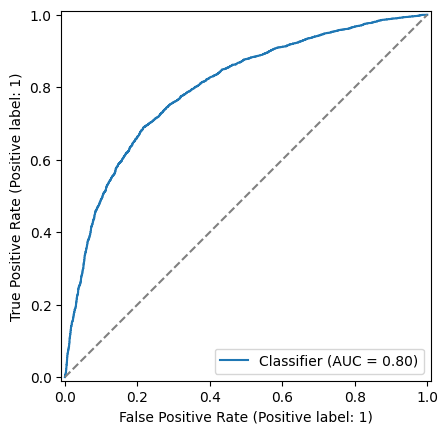

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, RocCurveDisplay

if READY and result is not None:
    if MODEL == "logistic":
        train, test = train_test_split(data, test_size=0.2, random_state=42, stratify=data[OUTCOME])
        holdout = smf.logit(formula, data=train).fit(disp=False)
        prob = holdout.predict(test)
        auc = roc_auc_score(test[OUTCOME], prob)
        print(f"Held-out AUC: {auc:.3f} (train n = {len(train):,}, test n = {len(test):,})")
        RocCurveDisplay.from_predictions(test[OUTCOME], prob)
        plt.plot([0, 1], [0, 1], "--", color="grey")
        plt.show()
    else:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.scatter(result.fittedvalues, result.resid, s=5, alpha=0.3)
        ax.axhline(0, color="grey", linestyle="--")
        ax.set_xlabel("Fitted value")
        ax.set_ylabel("Residual")
        plt.tight_layout()
        plt.show()


Sensitivity Check: Does each factor add anything beyond age and blood pressure? And does glucose look different when cholesterol is left out?

I reran the model with different predictors to see what cholesterol and glucose add beyond age and blood pressure.

To check each predictor, I removed and added #'s and ran them individually.

| Run | Predictors | Held-out AUC | Chol above normal | Chol well above normal | Gluc above normal | Gluc well above normal |
|---|---|---|---|---|---|---|
| 1 | Age + BP | ~0.79 | not in model | not in model | not in model | not in model |
| 2 | Age + BP + cholesterol | ~0.80 | ~1.46 (1.37 to 1.55) | ~2.70 (2.51 to 2.90) | not in model | not in model |
| 3 | Age + BP + glucose | ~0.79 | not in model | not in model | ~1.22 (1.12 to 1.33) | ~1.41 (1.30 to 1.53) |
| 4 | Age + BP + cholesterol + glucose (main model) | 0.798 | 1.45 (1.36 to 1.55) | 3.09 (2.84 to 3.37) | 1.04 (0.95 to 1.13) | 0.74 (0.68 to 0.82) |


### Model comparison: what do cholesterol and glucose add beyond age and blood pressure?

Fits all four models in one run, so the comparison table above can be reproduced exactly. For each model: AUC on the same held-out 20% of women, the gain over the base model with a bootstrap 95% confidence interval (500 resamples), and a likelihood-ratio test of whether the extra variables improve the fit.

In [ ]:
from scipy import stats

MODELS = {
    "1. Age + systolic BP": "cardio ~ age_years + ap_hi",
    "2. + cholesterol": "cardio ~ age_years + ap_hi + C(cholesterol_level)",
    "3. + glucose": "cardio ~ age_years + ap_hi + C(gluc_level)",
    "4. + cholesterol + glucose": "cardio ~ age_years + ap_hi + C(cholesterol_level) + C(gluc_level)",
}
def level_ors(fit, prefix):
    """Odds ratios for the above-normal and well-above-normal levels, or blank if the variable is not in the model."""
    keys = [f"{prefix}[T.above normal]", f"{prefix}[T.well above normal]"]
    if keys[0] not in fit.params.index:
        return ""
    return " / ".join(f"{np.exp(fit.params[k]):.2f}" for k in keys)

if READY and result is not None:
    train, test = train_test_split(data, test_size=0.2, random_state=42, stratify=data[OUTCOME])
    y = test[OUTCOME].to_numpy()
    base = MODELS["1. Age + systolic BP"]
    base_fit = smf.logit(base, data=data).fit(disp=False)
    base_prob = smf.logit(base, data=train).fit(disp=False).predict(test).to_numpy()
    base_auc = roc_auc_score(y, base_prob)
    rng = np.random.default_rng(0)

    rows = []
    for name, formula_i in MODELS.items():
        prob = smf.logit(formula_i, data=train).fit(disp=False).predict(test).to_numpy()
        fit = smf.logit(formula_i, data=data).fit(disp=False)
        auc_i = roc_auc_score(y, prob)
        row = {"Model": name, "Held-out AUC": round(auc_i, 3), "Gain vs model 1": "", "Gain 95% CI": "", "LR test p": ""}
        extra_df = fit.df_model - base_fit.df_model
        if extra_df > 0:
            boots = []
            for _ in range(500):
                i = rng.integers(0, len(y), len(y))
                boots.append(roc_auc_score(y[i], prob[i]) - roc_auc_score(y[i], base_prob[i]))
            p = stats.chi2.sf(2 * (fit.llf - base_fit.llf), extra_df)
            row.update({"Gain vs model 1": f"{auc_i - base_auc:+.3f}",
                        "Gain 95% CI": f"{np.percentile(boots, 2.5):+.3f} to {np.percentile(boots, 97.5):+.3f}",
                        "LR test p": "< 0.001" if p < 0.001 else f"{p:.3f}"})
        row["Cholesterol OR (above / well above)"] = level_ors(fit, "C(cholesterol_level)")
        row["Glucose OR (above / well above)"] = level_ors(fit, "C(gluc_level)")
        rows.append(row)
    comparison = pd.DataFrame(rows)
    display(comparison)

### Robustness checks: does the cholesterol result hold under other reasonable choices?

Each row refits the main model with one decision changed: adding other risk factors, adding diastolic BP, treating systolic BP as bands instead of a straight line, or cleaning the raw data with stricter blood pressure ranges (systolic 90-200, diastolic 60-120 mmHg, same rules otherwise).

In [ ]:
MAIN = "cardio ~ age_years + ap_hi + C(cholesterol_level) + C(gluc_level)"
KEYS = [("Cholesterol well above normal", "C(cholesterol_level)[T.well above normal]"),
        ("Glucose well above normal", "C(gluc_level)[T.well above normal]")]
LEVEL_ORDER = ["normal", "above normal", "well above normal"]

def key_odds_ratios(fit):
    ci = fit.conf_int()
    return {label: f"{np.exp(fit.params[k]):.2f} ({np.exp(ci.loc[k, 0]):.2f} to {np.exp(ci.loc[k, 1]):.2f})"
            for label, k in KEYS}

def clean_women(sbp_range, dbp_range):
    """Same rules as 01_cleaning.ipynb, with the blood pressure ranges as arguments."""
    w = pd.read_csv(TRACK / "data" / "cardiovascular_dataset_OpenBio_Final.csv", sep=";")
    w = w.drop_duplicates(subset="id")
    w["age_years"] = w["age"] / 365.25
    w = w.drop_duplicates(subset=[c for c in w.columns if c not in ("id", "age_years")])
    w = w[w["gender"] == 1].copy()
    for col, (low, high) in {"ap_hi": sbp_range, "ap_lo": dbp_range, "height": (130, 200), "weight": (35, 200)}.items():
        w = w[w[col].between(low, high)]
    w = w[w["ap_hi"] > w["ap_lo"]].copy()
    for col in ("cholesterol", "gluc"):
        w[col + "_level"] = pd.Categorical(w[col].map({1: "normal", 2: "above normal", 3: "well above normal"}),
                                           categories=LEVEL_ORDER, ordered=True)
    return w

if READY and result is not None:
    d_rob = df.copy()
    d_rob["sbp_band"] = pd.cut(d_rob["ap_hi"], [0, 119, 129, 139, 149, 999],
                               labels=["<120", "120-129", "130-139", "140-149", "150+"])
    checks = {
        "Main model": (MAIN, d_rob),
        "+ BMI, smoking, alcohol, activity": (MAIN + " + bmi + smoke + alco + active", d_rob),
        "+ diastolic BP": (MAIN + " + ap_lo", d_rob),
        "Systolic BP in bands": (MAIN.replace("ap_hi", "C(sbp_band)"), d_rob),
        "Stricter cleaning ranges": (MAIN, clean_women((90, 200), (60, 120))),
    }
    rows = []
    for label, (f, d_check) in checks.items():
        rows.append({"Check": label, "Women": f"{len(d_check):,}", **key_odds_ratios(smf.logit(f, data=d_check).fit(disp=False))})
    display(pd.DataFrame(rows))

    strict = checks["Stricter cleaning ranges"][1]
    s_train, s_test = train_test_split(strict, test_size=0.2, random_state=42, stratify=strict[OUTCOME])
    s_aucs = [roc_auc_score(s_test[OUTCOME], smf.logit(f, data=s_train).fit(disp=False).predict(s_test))
              for f in ("cardio ~ age_years + ap_hi", MAIN)]
    print(f"Stricter cleaning: AUC {s_aucs[0]:.3f} -> {s_aucs[1]:.3f} (gain {s_aucs[1] - s_aucs[0]:+.3f}) with cholesterol and glucose added")

### Calibration: do the model's predicted chances match what actually happened?

Held-out women are split into 10 equal groups by predicted chance. A well-calibrated model's predicted and actual rates line up on the diagonal. This matters because our headline visual reports predicted chances.

In [ ]:
if READY and result is not None and MODEL == "logistic":
    cal_train, cal_test = train_test_split(data, test_size=0.2, random_state=42, stratify=data[OUTCOME])
    cal_prob = smf.logit(formula, data=cal_train).fit(disp=False).predict(cal_test)
    cal = pd.DataFrame({"predicted": cal_prob, "actual": cal_test[OUTCOME]})
    cal["group"] = pd.qcut(cal["predicted"], 10, labels=False, duplicates="drop")
    cal = cal.groupby("group").agg(predicted=("predicted", "mean"), actual=("actual", "mean"), women=("actual", "size"))
    cal["gap (points)"] = 100 * (cal["actual"] - cal["predicted"])
    display(cal.assign(predicted=100 * cal["predicted"], actual=100 * cal["actual"]).round(1))
    print(f"Average gap: {cal['gap (points)'].abs().mean():.1f} percentage points; largest gap: {cal['gap (points)'].abs().max():.1f}")

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot([0, 100], [0, 100], "--", color="grey", label="Perfect match")
    ax.plot(100 * cal["predicted"], 100 * cal["actual"], "o-", color="#C8243C", label="Our model")
    ax.set_xlabel("Predicted chance of CVD (%)")
    ax.set_ylabel("Actual share of women with CVD (%)")
    ax.set_title("Predicted vs actual CVD in held-out women")
    ax.legend()
    plt.tight_layout()
    fig.savefig(FIGURES / "calibration.png", dpi=200)
    plt.show()

### CVD rate at each combination of cholesterol and glucose level

The main model gives glucose a single odds ratio. This table shows the raw share of women with CVD in each cholesterol and glucose group, to see where that result comes from.

In [8]:
if READY:
    rate = (data.groupby(["cholesterol_level", "gluc_level"], observed=True)[OUTCOME].mean() * 100).round(1).unstack()
    print("Women with CVD (%), by cholesterol level (rows) and glucose level (columns):")
    display(rate)
    print("Number of women in each group:")
    display(pd.crosstab(data["cholesterol_level"], data["gluc_level"]))

Women with CVD (%), by cholesterol level (rows) and glucose level (columns):


gluc_level,normal,above normal,well above normal
cholesterol_level,,,
normal,42.5,52.3,48.3
above normal,58.0,57.2,61.7
well above normal,82.9,81.2,69.1


Number of women in each group:


gluc_level,normal,above normal,well above normal
cholesterol_level,,,
normal,30666,1369,927
above normal,4383,1622,243
well above normal,2680,351,2398


### How often do high glucose and high cholesterol occur together?

In [ ]:
if READY:
    high_gluc = df[df["gluc_level"] == "well above normal"]
    both = (high_gluc["cholesterol_level"] == "well above normal").sum()
    print(f"Women with well above normal glucose: {len(high_gluc):,}; of these, {both:,} "
          f"({100 * both / len(high_gluc):.1f}%) also have well above normal cholesterol")

### Predicted chance for one example woman, and a raw-data check

The model's predicted chance of CVD for a 54-year-old woman with systolic BP 120 mmHg and normal glucose, at each cholesterol level, with 95% confidence intervals. Then the raw CVD rates among real women who match that profile (aged 50 to 58, systolic BP exactly 120, normal glucose), as a check that does not depend on the model.

In [ ]:
if READY and result is not None and MODEL == "logistic":
    levels = ["normal", "above normal", "well above normal"]
    example = pd.DataFrame({
        "age_years": [54] * 3,
        "ap_hi": [120] * 3,
        "cholesterol_level": pd.Categorical(levels, categories=levels, ordered=True),
        "gluc_level": pd.Categorical(["normal"] * 3, categories=levels, ordered=True),
    })
    pred = result.get_prediction(example).summary_frame(alpha=0.05)
    pred.index = levels
    display((100 * pred[["predicted", "ci_lower", "ci_upper"]]).round(1)
            .rename(columns={"predicted": "Predicted CVD %", "ci_lower": "95% CI low", "ci_upper": "95% CI high"}))

    match = df[df["age_years"].between(50, 58) & (df["ap_hi"] == 120) & (df["gluc_level"] == "normal")]
    raw_check = match.groupby("cholesterol_level", observed=True)[OUTCOME].agg(["size", "mean"])
    se = np.sqrt(raw_check["mean"] * (1 - raw_check["mean"]) / raw_check["size"])
    raw_check["Observed CVD %"] = (100 * raw_check["mean"]).round(1)
    raw_check["95% CI"] = [f"{100 * (m - 1.96 * e):.1f} to {100 * (m + 1.96 * e):.1f}" for m, e in zip(raw_check["mean"], se)]
    print("Raw check: women aged 50-58, systolic BP 120, normal glucose")
    display(raw_check[["size", "Observed CVD %", "95% CI"]].rename(columns={"size": "Women"}))

## Step 5: Interpret

Write your main result as one plain sentence with the effect size and its confidence interval, then check it against the [ground rules](../../README.md#ground-rules). Say "associated with," not "causes."

Among 44,639 women aged 30 to 65, well above normal cholesterol was associated with about three times the odds of cardiovascular disease compared with normal cholesterol (OR 3.09, 95% CI 2.84 to 3.37), after accounting for age, systolic blood pressure and glucose.

## Step 6: Headline visual

One graph for a non-specialist, used in both the video and the article. It shows the model's predicted chance of CVD as dots out of 100 women who share the same age (54), systolic BP (120 mmHg) and normal glucose, and differ only in cholesterol. The numbers come from the prediction cell above.

In [ ]:
if READY and result is not None and MODEL == "logistic":
    counts = [int(round(v)) for v in 100 * pred["predicted"]]
    lows = [int(round(v)) for v in 100 * pred["ci_lower"]]
    highs = [int(round(v)) for v in 100 * pred["ci_upper"]]
    names = ["Normal cholesterol", "Above normal cholesterol", "Well above normal cholesterol"]
    colors = ["#E77A86", "#C8243C", "#8E1530"]

    fig, axes = plt.subplots(1, 3, figsize=(13, 7))
    fig.patch.set_facecolor("#FBF3F0")
    plt.subplots_adjust(left=0.03, right=0.97, top=0.74, bottom=0.2, wspace=0.12)
    for ax, n, lo, hi, name, color in zip(axes, counts, lows, highs, names, colors):
        ax.set_facecolor("#FBF3F0")
        for k in range(100):
            row, col = divmod(k, 10)  # fills from the bottom row up, left to right
            ax.add_patch(plt.Circle((col, row), 0.38, color=color if k < n else "#EBCFD0"))
        ax.set_xlim(-0.6, 9.6)
        ax.set_ylim(-0.6, 9.6)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title(f"{n} in 100", fontsize=26, fontweight="bold", color=color, loc="left", pad=10)
        ax.text(-0.5, -1.3, name, fontsize=14, fontweight="bold", color="#2A0E18", va="top")
        ax.text(-0.5, -2.4, f"95% CI {lo} to {hi}", fontsize=12, color="#7A5E66", va="top")
    fig.text(0.03, 0.95, f"Same age, same blood pressure: {counts[0]} vs {counts[2]} in 100 women",
             fontsize=22, fontweight="bold", color="#2A0E18", va="top")
    fig.text(0.03, 0.885, "Predicted chance of cardiovascular disease for women aged 54 with systolic BP 120 mmHg "
             "and normal glucose, by cholesterol level", fontsize=13, color="#5A4048", va="top")
    fig.text(0.03, 0.03, "Source: our logistic regression model of 44,639 women (OpenBio Datathon Dataset 1). "
             "An association, not proof of cause. Not medical advice.", fontsize=11, color="#7A5E66")
    fig.savefig(FIGURES / "headline.png", dpi=300, facecolor=fig.get_facecolor())
    plt.show()
    print("Saved", FIGURES / "headline.png")

## Figures for the article

Saves the article's figures to `team/figures/`, each with a title and labeled axes. Uses the same colors as the slides: grey for age and blood pressure, crimson for cholesterol, blue for glucose.

In [ ]:
if READY and result is not None and MODEL == "logistic":
    CRIMSON, BLUE, GREY, DEEP = "#C8243C", "#2D6A8A", "#8F7D83", "#8E1530"
    LEVELS = ["normal", "above normal", "well above normal"]
    NICE = ["Normal", "Above normal", "Well above normal"]

    def log_axis(ax, ticks):
        ax.set_xscale("log")
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"{t:g}" for t in ticks])
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
        ax.spines[["top", "right"]].set_visible(False)

    # Figure 1: raw CVD rates by cholesterol and by glucose level
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
    for ax, col, color, name in [(axes[0], "cholesterol_level", CRIMSON, "Cholesterol"),
                                 (axes[1], "gluc_level", BLUE, "Glucose")]:
        rates = 100 * df.groupby(col, observed=True)[OUTCOME].mean().reindex(LEVELS)
        bars = ax.bar(NICE, rates.values, color=color, width=0.6)
        ax.bar_label(bars, labels=[f"{v:.0f}%" for v in rates.values], padding=3, fontsize=12)
        ax.set_xlabel(f"{name} level recorded at the exam")
        ax.set_ylim(0, 100)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Women with CVD (%)")
    fig.suptitle("Before adjusting, more women have CVD at higher cholesterol and glucose levels",
                 fontsize=14, x=0.01, ha="left")
    plt.tight_layout()
    fig.savefig(FIGURES / "fig1_raw_rates.png", dpi=200, bbox_inches="tight")
    plt.show()

    # Figure 2: adjusted odds ratios from the main model
    terms = [("C(cholesterol_level)[T.above normal]", "Cholesterol: above normal", CRIMSON),
             ("C(cholesterol_level)[T.well above normal]", "Cholesterol: well above normal", CRIMSON),
             ("C(gluc_level)[T.above normal]", "Glucose: above normal", BLUE),
             ("C(gluc_level)[T.well above normal]", "Glucose: well above normal", BLUE)]
    ci = result.conf_int()
    fig, ax = plt.subplots(figsize=(10, 4))
    for i, (k, label, color) in enumerate(terms):
        y_pos = len(terms) - 1 - i
        o, lo, hi = np.exp([result.params[k], ci.loc[k, 0], ci.loc[k, 1]])
        ax.plot([lo, hi], [y_pos, y_pos], color=color, linewidth=3)
        ax.plot(o, y_pos, "o", color=color, markersize=10)
        ax.text(4.4, y_pos, f"{o:.2f} ({lo:.2f} to {hi:.2f})", va="center", fontsize=11, color=color)
    ax.axvline(1, color="grey", linestyle="--")
    log_axis(ax, [0.5, 1, 2, 4])
    ax.set_xlim(0.5, 4.2)
    ax.set_yticks(range(len(terms))[::-1], [t[1] for t in terms])
    ax.set_xlabel("Odds ratio compared with a normal level (log scale; 1 = no difference)")
    ax.set_title("At the same age and blood pressure, cholesterol is linked to higher odds of CVD; glucose is not",
                 fontsize=12, loc="left")
    plt.tight_layout()
    fig.savefig(FIGURES / "fig2_adjusted_odds.png", dpi=200, bbox_inches="tight")
    plt.show()

    # Figure 3: glucose odds ratios without and with cholesterol in the model
    gluc_only = smf.logit("cardio ~ age_years + ap_hi + C(gluc_level)", data=data).fit(disp=False)
    g_terms = [("C(gluc_level)[T.above normal]", "Glucose: above normal"),
               ("C(gluc_level)[T.well above normal]", "Glucose: well above normal")]
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for fit, label, color, shift in [(gluc_only, "Model without cholesterol (age + BP + glucose)", GREY, 0.15),
                                     (result, "Model with cholesterol (main model)", BLUE, -0.15)]:
        c = fit.conf_int()
        for i, (k, _) in enumerate(g_terms):
            y_pos = len(g_terms) - 1 - i + shift
            o, lo, hi = np.exp([fit.params[k], c.loc[k, 0], c.loc[k, 1]])
            ax.plot([lo, hi], [y_pos, y_pos], color=color, linewidth=3)
            ax.plot(o, y_pos, "o", color=color, markersize=9, label=label if i == 0 else None)
            ax.text(2.05, y_pos, f"{o:.2f} ({lo:.2f} to {hi:.2f})", va="center", fontsize=11, color=color)
    ax.axvline(1, color="grey", linestyle="--")
    log_axis(ax, [0.5, 1, 2])
    ax.set_xlim(0.5, 2)
    ax.set_yticks([1, 0], [t[1] for t in g_terms])
    ax.set_xlabel("Odds ratio compared with normal glucose (log scale; 1 = no difference)")
    ax.set_title("Glucose's link to CVD flips once cholesterol is in the model", fontsize=12, loc="left")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)
    plt.tight_layout()
    fig.savefig(FIGURES / "fig3_glucose_flip.png", dpi=200, bbox_inches="tight")
    plt.show()

    # Figure 4: held-out AUC of the four models
    labels4 = ["Age + systolic BP", "+ cholesterol", "+ glucose", "+ cholesterol + glucose"]
    y_pos = np.arange(len(comparison))[::-1]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(y_pos, comparison["Held-out AUC"] - 0.5, left=0.5, color=[GREY, CRIMSON, BLUE, DEEP], height=0.6)
    for yp, auc_i, gain in zip(y_pos, comparison["Held-out AUC"], comparison["Gain vs model 1"]):
        ax.text(auc_i + 0.005, yp, f"{auc_i:.3f}" + (f"  ({gain})" if gain else ""), va="center", fontsize=11)
    ax.set_yticks(y_pos, labels4)
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel("AUC on held-out women (0.5 = coin flip, 1.0 = perfect)")
    ax.set_title("Adding cholesterol barely improves prediction; glucose adds almost nothing", fontsize=12, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    fig.savefig(FIGURES / "fig4_auc.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved fig1_raw_rates.png, fig2_adjusted_odds.png, fig3_glucose_flip.png and fig4_auc.png to", FIGURES)

---

This notebook is part of a student data analysis. It is not medical advice, a diagnostic tool or clinical guidance.